In [ ]:
!pip install transformers accelerate datasets torchaudio librosa tqdm

In [ ]:
import zipfile
import os

# SAVEEE zip file
saveee_zip_path = "/content/saveee.zip"

# Output folder
saveee_output_folder = "/content/SAVEEE_DATA"

# Create folder
os.makedirs(saveee_output_folder, exist_ok=True)

# Extract zip
with zipfile.ZipFile(saveee_zip_path, "r") as zip_ref:
    zip_ref.extractall(saveee_output_folder)

print("SAVEEE Dataset Extracted Successfully!")
print("Contents:", os.listdir(saveee_output_folder))

SAVEEE Dataset Extracted Successfully!
Contents: ['audiodata', 'AudioData']


In [ ]:
import glob

saveee_wavs = glob.glob("/content/SAVEEE_DATA/**/*.wav", recursive=True)

print("Total SAVEEE WAV Files:", len(saveee_wavs))
print("Sample File:", saveee_wavs[0])

Total SAVEEE WAV Files: 960
Sample File: /content/SAVEEE_DATA/audiodata/AudioData/JK/d07.wav


In [ ]:
import zipfile
import os

# CRAMA-D zip file
crama_zip_path = "/content/crama-d.zip"

# Output folder
crama_output_folder = "/content/CRAMA-D_DATA"

# Create folder
os.makedirs(crama_output_folder, exist_ok=True)

# Extract zip
with zipfile.ZipFile(crama_zip_path, "r") as zip_ref:
    zip_ref.extractall(crama_output_folder)

print("CRAMA-D Dataset Extracted Successfully!")
print("Contents:", os.listdir(crama_output_folder))

CRAMA-D Dataset Extracted Successfully!
Contents: ['AudioWAV']


In [ ]:
crama_wavs = glob.glob("/content/CRAMA-D_DATA/**/*.wav", recursive=True)

print("Total CRAMA-D WAV Files:", len(crama_wavs))
print("Sample File:", crama_wavs[0])

Total CRAMA-D WAV Files: 7442
Sample File: /content/CRAMA-D_DATA/AudioWAV/1001_IOM_SAD_XX.wav


In [ ]:
import os, glob
import numpy as np
import pandas as pd
import librosa
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from datasets import Dataset

from transformers import (
    Wav2Vec2Processor,
    Wav2Vec2ForSequenceClassification,
    TrainingArguments,
    Trainer
)

import warnings
warnings.filterwarnings("ignore")

print("Transformers Version:", __import__("transformers").__version__)
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

Transformers Version: 5.0.0
GPU Available: True
GPU Name: Tesla T4


In [ ]:
savee_files = glob.glob("/content/SAVEEE_DATA/**/*.wav", recursive=True)
crema_files = glob.glob("/content/CRAMA-D_DATA/**/*.wav", recursive=True)

paths = savee_files + crema_files

print("Total SAVEE Files:", len(savee_files))
print("Total CREMA Files:", len(crema_files))
print("Total Combined Files:", len(paths))

Total SAVEE Files: 960
Total CREMA Files: 7442
Total Combined Files: 8402


In [ ]:
def get_savee_label(file):
    name = file.split("/")[-1]
    if "_" in name:
        emotion_part = name.split("_")[1]
    else:
        emotion_part = name

    if emotion_part.startswith("a"): return "angry"
    if emotion_part.startswith("d"): return "disgust"
    if emotion_part.startswith("f"): return "fear"
    if emotion_part.startswith("h"): return "happy"
    if emotion_part.startswith("n"): return "neutral"
    if emotion_part.startswith("sa"): return "sad"
    if emotion_part.startswith("su"): return "surprise"
    return "unknown"


def get_crema_label(file):
    parts = file.split("/")[-1].split("_")
    if len(parts) < 3:
        return "unknown"
    emotion_code = parts[2]

    mapping = {
        "ANG": "angry",
        "DIS": "disgust",
        "FEA": "fear",
        "HAP": "happy",
        "NEU": "neutral",
        "SAD": "sad"
    }
    return mapping.get(emotion_code, "unknown")

In [ ]:
labels = []
for file in paths:
    if "SAVEEE_DATA" in file:
        labels.append(get_savee_label(file))
    else:
        labels.append(get_crema_label(file))

df = pd.DataFrame({"path": paths, "label": labels})
df = df[df["label"] != "unknown"]

print(df["label"].value_counts())
print("df created successfully")

label
disgust     1391
sad         1391
happy       1391
fear        1391
angry       1391
neutral     1327
surprise     120
Name: count, dtype: int64
df created successfully


In [ ]:
df = df.groupby("label").sample(1200, replace=True)
print("Balanced Dataset Count:\n")
print(df["label"].value_counts())


Balanced Dataset Count:

label
angry       1200
disgust     1200
fear        1200
happy       1200
neutral     1200
sad         1200
surprise    1200
Name: count, dtype: int64


In [ ]:
encoder = LabelEncoder()
df["label_id"] = encoder.fit_transform(df["label"])

num_labels = len(encoder.classes_)
print("Emotion Classes:", encoder.classes_)
print("num_labels:", num_labels)

Emotion Classes: ['angry' 'disgust' 'fear' 'happy' 'neutral' 'sad' 'surprise']
num_labels: 7


In [ ]:
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label_id"]
)

train_dataset = Dataset.from_pandas(train_df)
test_dataset = Dataset.from_pandas(test_df)

print("Train Size:", len(train_dataset))
print("Test Size:", len(test_dataset))

Train Size: 6720
Test Size: 1680


In [ ]:
processor = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base")
print("Processor Loaded")

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

Processor Loaded


In [ ]:
def preprocess(batch):
    audio, sr = librosa.load(batch["path"], sr=16000)
    inputs = processor(audio, sampling_rate=16000)
    batch["input_values"] = inputs["input_values"][0]
    batch["labels"] = batch["label_id"]
    return batch

train_dataset = train_dataset.map(preprocess)
test_dataset = test_dataset.map(preprocess)

print("Preprocessing Done")

Map:   0%|          | 0/6720 [00:00<?, ? examples/s]

Map:   0%|          | 0/1680 [00:00<?, ? examples/s]

Preprocessing Done


In [ ]:
def collate_fn(batch):
    import torch

    # Convert input_values to float tensors
    input_values = [torch.tensor(x["input_values"], dtype=torch.float32) for x in batch]

    # Convert labels to long tensors (FIXED TYPO HERE)
    labels = torch.tensor([x["labels"] for x in batch], dtype=torch.long)

    # Pad sequences
    input_values = torch.nn.utils.rnn.pad_sequence(
        input_values,
        batch_first=True,
        padding_value=0.0
    )

    # Create attention mask
    attention_mask = (input_values != 0).long()

    return {
        "input_values": input_values,
        "attention_mask": attention_mask,
        "labels": labels
    }


In [ ]:
def preprocess(batch):
    audio, sr = librosa.load(batch["path"], sr=16000)

    processed = processor(
        audio,
        sampling_rate=16000,
        padding=True,
        truncation=True,
        max_length=16000 * 6   # 6 seconds instead of 3
    )

    batch["input_values"] = processed["input_values"][0]
    batch["labels"] = int(batch["label_id"])

    return batch

In [ ]:
train_dataset = train_dataset.remove_columns(
    [col for col in train_dataset.column_names if col not in ["input_values", "labels"]]
)

test_dataset = test_dataset.remove_columns(
    [col for col in test_dataset.column_names if col not in ["input_values", "labels"]]
)

In [ ]:
print(train_dataset.column_names)

['input_values', 'labels']


In [ ]:
model = Wav2Vec2ForSequenceClassification.from_pretrained(
    "facebook/wav2vec2-base",
    num_labels=num_labels
)

model.freeze_feature_encoder()
print("Model Loaded + Feature Encoder Frozen")

pytorch_model.bin:   0%|          | 0.00/380M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Wav2Vec2ForSequenceClassification LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     | 
-----------------------------+------------+-
project_q.bias               | UNEXPECTED | 
project_hid.bias             | UNEXPECTED | 
quantizer.weight_proj.bias   | UNEXPECTED | 
project_hid.weight           | UNEXPECTED | 
project_q.weight             | UNEXPECTED | 
quantizer.codevectors        | UNEXPECTED | 
quantizer.weight_proj.weight | UNEXPECTED | 
classifier.weight            | MISSING    | 
classifier.bias              | MISSING    | 
projector.weight             | MISSING    | 
projector.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model Loaded + Feature Encoder Frozen


In [ ]:
training_args = TrainingArguments(
    output_dir="./wav2vec2-ser",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=1e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    num_train_epochs=8,
    warmup_steps=200,
    weight_decay=0.01,
    logging_strategy="epoch",
    report_to="none",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    save_total_limit=2
)

In [ ]:
def compute_metrics(pred):
    logits, labels = pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds)}

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    data_collator=collate_fn,
    compute_metrics=compute_metrics
)

print("Trainer Ready")

Trainer Ready


In [ ]:
from transformers import TrainerCallback

class GradualUnfreezeCallback(TrainerCallback):
    def on_epoch_end(self, args, state, control, **kwargs):

        # Stage 1: unfreeze feature extractor
        if int(state.epoch) == 3:
            model.wav2vec2.feature_extractor._freeze_parameters = False
            print("Feature extractor unfrozen (epoch 3)")

        # Stage 2: unfreeze full encoder
        if int(state.epoch) == 6:
            for param in model.wav2vec2.parameters():
                param.requires_grad = True
            print("Full encoder unfrozen (epoch 6)")

trainer.add_callback(GradualUnfreezeCallback())

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,1.368584,0.994867,0.649405
2,0.822111,0.724436,0.764286
3,0.646310,0.648655,0.820833
4,0.544670,0.712452,0.830952
5,0.473017,0.711981,0.847024
6,0.401221,0.728464,0.839286
7,0.341729,0.717246,0.867262
8,0.314830,0.727574,0.866667


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Feature extractor unfrozen (epoch 3)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=13440, training_loss=0.6140591258094424, metrics={'train_runtime': 6330.3966, 'train_samples_per_second': 8.492, 'train_steps_per_second': 2.123, 'total_flos': 1.8393670507610767e+18, 'train_loss': 0.6140591258094424, 'epoch': 8.0})

In [ ]:
results = trainer.evaluate()
print("Final Accuracy:", results["eval_accuracy"]*100, "%")

Final Accuracy: 86.72619047619048 %


In [ ]:
training_args.fp16 = True
print("FP16 enabled for T4")

FP16 enabled for T4


In [ ]:
training_args.per_device_train_batch_size = 8
training_args.per_device_eval_batch_size = 8
print("Batch size optimized for Tesla T4")


Batch size optimized for Tesla T4


In [ ]:
training_args.learning_rate = 2e-6
print("Learning rate reduced")

Learning rate reduced


In [ ]:
training_args.learning_rate = 2e-6
training_args.lr_scheduler_type = "cosine"
training_args.warmup_ratio = 0.1

print("LR tuned for emotional generalization")

LR tuned for emotional generalization


In [ ]:
training_args.num_train_epochs = 15
print("Epoch count increased")

Epoch count increased


In [ ]:
training_args.lr_scheduler_type = "cosine"
training_args.warmup_ratio = 0.1
print("Cosine scheduler enabled")

Cosine scheduler enabled


In [ ]:
training_args.weight_decay = 0.02
print("Regularization increased")


Regularization increased


In [ ]:
training_args.label_smoothing_factor = 0.1
print("Label smoothing enabled")

Label smoothing enabled


In [ ]:
training_args.max_grad_norm = 1.0
print("Gradient clipping enabled")

Gradient clipping enabled


In [ ]:
training_args.warmup_ratio = 0.15
print("Warmup increased")


Warmup increased


In [ ]:
model.config.apply_spec_augment = True
model.config.mask_time_prob = 0.08
model.config.mask_feature_prob = 0.05

print("SpecAugment enabled")

SpecAugment enabled


In [ ]:
model.config.hidden_dropout = 0.2
model.config.attention_dropout = 0.2
model.config.final_dropout = 0.2

print("Dropout increased")

Dropout increased


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import torch

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["label_id"]),
    y=train_df["label_id"]
)

class_weights = torch.tensor(class_weights, dtype=torch.float).cuda()
print("Class weights:", class_weights)


Class weights: tensor([1., 1., 1., 1., 1., 1., 1.], device='cuda:0')


In [ ]:
import torch
import torch.nn.functional as F

class FocalLoss(torch.nn.Module):
    def __init__(self, gamma=2):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce)
        loss = ((1 - pt) ** self.gamma) * ce
        return loss.mean()

In [ ]:
def compute_loss(model, inputs, return_outputs=False):
    labels = inputs.get("labels")
    outputs = model(**inputs)
    logits = outputs.get("logits")

    loss_fn = FocalLoss()
    loss = loss_fn(logits, labels)

    return (loss, outputs) if return_outputs else loss


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    data_collator=collate_fn,
    compute_metrics=compute_metrics
)

print("Trainer Ready")

Trainer Ready


In [ ]:
from transformers import TrainerCallback

class GradualUnfreezeCallback(TrainerCallback):
    def on_epoch_end(self, args, state, control, **kwargs):

        if int(state.epoch) == 3:
            model.wav2vec2.feature_extractor._freeze_parameters = False
            print("Feature extractor unfrozen")

        if int(state.epoch) == 6:
            for param in model.wav2vec2.parameters():
                param.requires_grad = True
            print("Full encoder unfrozen")

trainer.add_callback(GradualUnfreezeCallback())


In [ ]:
torch.cuda.empty_cache()

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.763650,0.816034,0.865476
2,0.631603,0.847846,0.855952
3,0.616550,0.820097,0.872619
4,0.606609,0.847081,0.864881
5,0.595527,0.825852,0.875000
6,0.583852,0.831057,0.864286
7,0.572018,0.819357,0.882143
8,0.565924,0.838476,0.871429
9,0.558930,0.822760,0.876786
10,0.562835,0.828425,0.872619


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Feature extractor unfrozen


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (9 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=12600, training_loss=0.5870036243257069, metrics={'train_runtime': 14402.27, 'train_samples_per_second': 6.999, 'train_steps_per_second': 0.875, 'total_flos': 3.944946836747128e+18, 'train_loss': 0.5870036243257069, 'epoch': 15.0})

In [ ]:
results = trainer.evaluate()
print("Final Boosted Accuracy:", results["eval_accuracy"] * 100, "%")

Final Boosted Accuracy: 88.21428571428571 %


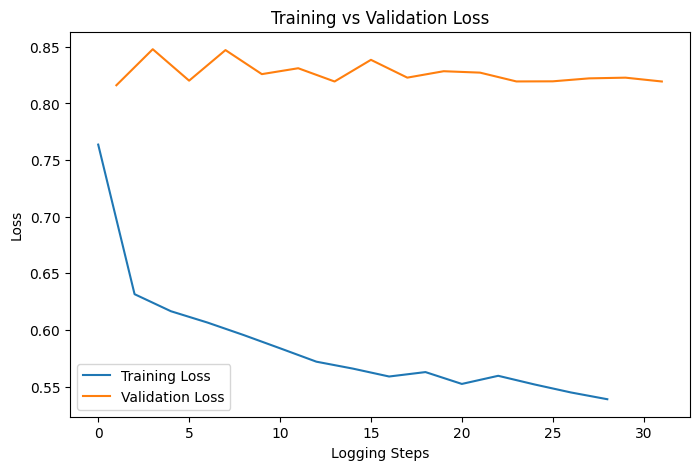

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Extract log history
logs = trainer.state.log_history
df_logs = pd.DataFrame(logs)

plt.figure(figsize=(8,5))

if "loss" in df_logs:
    plt.plot(df_logs["loss"].dropna(), label="Training Loss")

if "eval_loss" in df_logs:
    plt.plot(df_logs["eval_loss"].dropna(), label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Logging Steps")
plt.ylabel("Loss")
plt.legend()
plt.show()

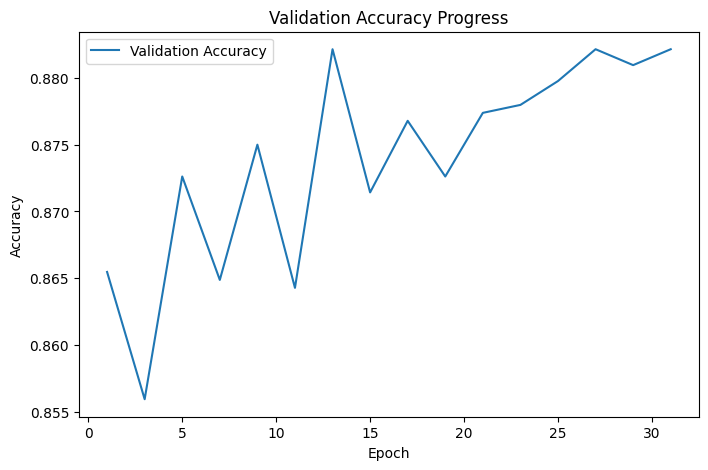

In [ ]:
plt.figure(figsize=(8,5))

if "eval_accuracy" in df_logs:
    plt.plot(df_logs["eval_accuracy"].dropna(), label="Validation Accuracy")

plt.title("Validation Accuracy Progress")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

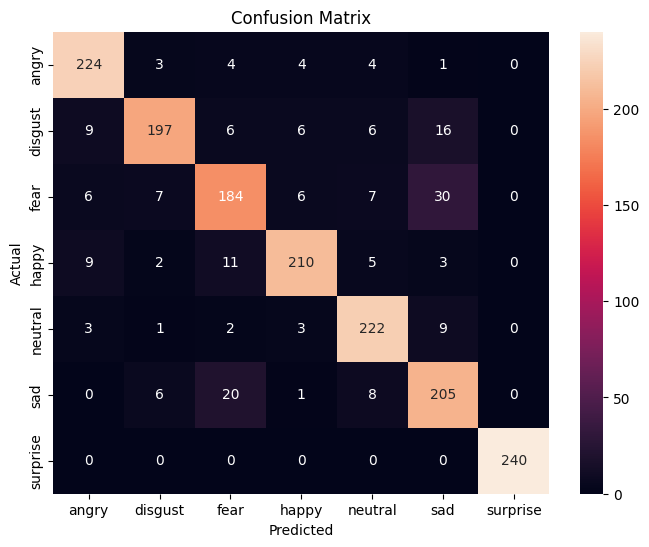

              precision    recall  f1-score   support

       angry       0.89      0.93      0.91       240
     disgust       0.91      0.82      0.86       240
        fear       0.81      0.77      0.79       240
       happy       0.91      0.88      0.89       240
     neutral       0.88      0.93      0.90       240
         sad       0.78      0.85      0.81       240
    surprise       1.00      1.00      1.00       240

    accuracy                           0.88      1680
   macro avg       0.88      0.88      0.88      1680
weighted avg       0.88      0.88      0.88      1680



In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

predictions = trainer.predict(test_dataset)

y_true = predictions.label_ids
y_pred = np.argmax(predictions.predictions, axis=1)

labels = encoder.classes_

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Classification Report
print(classification_report(y_true, y_pred, target_names=labels))

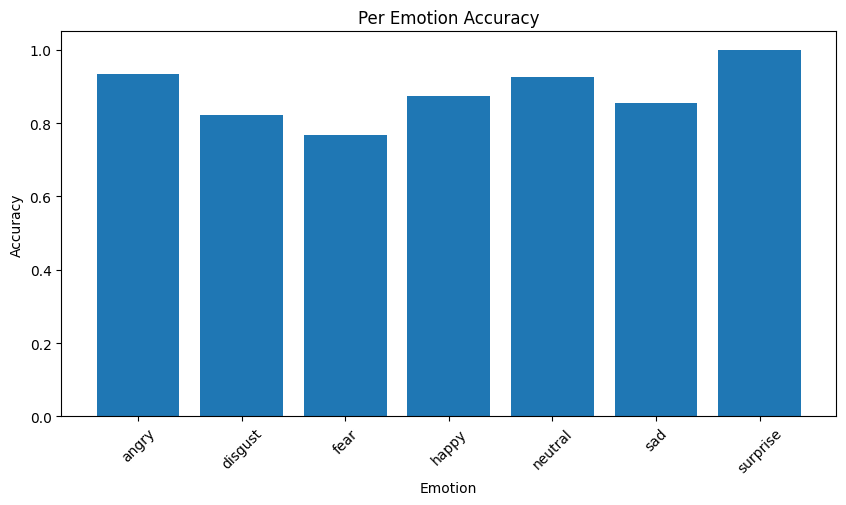

In [ ]:
import numpy as np

emotion_acc = {}

for i, emotion in enumerate(encoder.classes_):
    idx = np.where(y_true == i)[0]
    emotion_acc[emotion] = np.mean(y_pred[idx] == y_true[idx])

plt.figure(figsize=(10,5))
plt.bar(emotion_acc.keys(), emotion_acc.values())
plt.title("Per Emotion Accuracy")
plt.xlabel("Emotion")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.show()

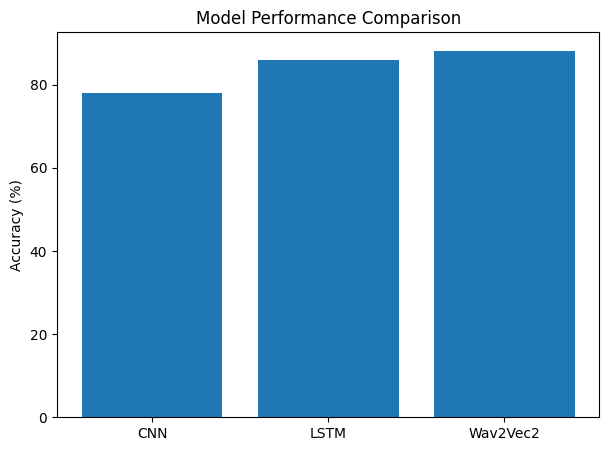

In [ ]:
models = ["CNN", "LSTM", "Wav2Vec2"]
accuracy = [78, 86, results["eval_accuracy"]*100]

plt.figure(figsize=(7,5))
plt.bar(models, accuracy)
plt.title("Model Performance Comparison")
plt.ylabel("Accuracy (%)")
plt.show()

In [ ]:
!ls -lh /content

total 2.5G
drwxr-xr-x 3 root root 4.0K Feb 20 05:58 CRAMA-D_DATA
-rw-r--r-- 1 root root 452M Feb 20 05:57 crama-d.zip
drwxr-xr-x 1 root root 4.0K Feb  6 14:31 sample_data
drwxr-xr-x 4 root root 4.0K Feb 20 05:58 SAVEEE_DATA
-rw-r--r-- 1 root root 215M Feb 20 05:53 saveee.zip
drwxr-xr-x 2 root root 4.0K Feb 20 14:39 SUBESCO
drwxr-xr-x 3 root root 4.0K Feb 20 12:13 SUBESCO_BANGLA_DATA
-rw-r--r-- 1 root root 586M Feb 20 14:49 SUBESCO.zip
-rw-r--r-- 1 root root 1.3G Feb 20 13:44 subo.zip
drwxr-xr-x 3 root root 4.0K Feb 20 12:48 wav2vec2-cross-lingual-en-bn
drwxr-xr-x 4 root root 4.0K Feb 20 11:55 wav2vec2-ser


In [ ]:
!rm -rf /content/subo.zip
!rm -rf /content/SUBESCO
!rm -rf /content/SUBESCO_BANGLA_DATA

In [ ]:
from google.colab import files

uploaded = files.upload()

KeyboardInterrupt: 

In [ ]:
import os

for f in os.listdir():
    print(f, os.path.getsize(f)/1024/1024, "MB")

In [ ]:
import zipfile, os

zip_path = "/content/subo.zip"
extract_path = "/content/SUBESCO"

os.makedirs(extract_path, exist_ok=True)

print("Extracting... this may take 2–5 mins")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction finished")

In [ ]:
import glob

audio_files_bn = glob.glob("/content/SUBESCO/**/*.wav", recursive=True)

print("Total Bengali audio files:", len(audio_files_bn))

In [ ]:
import pandas as pd

def parse_bn(filepath):
    name = os.path.basename(filepath).lower()

    mapping = {
        "ang": "angry",
        "hap": "happy",
        "sad": "sad",
        "neu": "neutral",
        "fea": "fear",
        "dis": "disgust",
        "sur": "surprise"
    }

    for k, v in mapping.items():
        if k in name:
            return v

    return "unknown"

df_bn = pd.DataFrame({
    "path": audio_files_bn,
    "label": [parse_bn(p) for p in audio_files_bn]
})

df_bn = df_bn[df_bn.label != "unknown"].copy()
df_bn["language"] = "bengali"

print(df_bn["label"].value_counts())

In [ ]:
df_en = df.copy()
df_en["language"] = "english"

common = set(df_en.label.unique()) & set(df_bn.label.unique())

df_en = df_en[df_en.label.isin(common)]
df_bn = df_bn[df_bn.label.isin(common)]

# 15% Bengali used for adaptation
bn_adapt = df_bn.sample(frac=0.15, random_state=42)
bn_test  = df_bn.drop(bn_adapt.index)

train_cross = pd.concat([df_en, bn_adapt]).reset_index(drop=True)
test_cross  = bn_test.reset_index(drop=True)

print("Adaptation train size:", len(train_cross))
print("Pure Bengali test size:", len(test_cross))

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder_cross = LabelEncoder()

train_cross["label_id"] = encoder_cross.fit_transform(train_cross["label"])
test_cross["label_id"]  = encoder_cross.transform(test_cross["label"])

num_labels_cross = len(encoder_cross.classes_)

print("Cross-lingual classes:", encoder_cross.classes_)

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder_cross = LabelEncoder()

train_cross["label_id"] = encoder_cross.fit_transform(train_cross["label"])
test_cross["label_id"]  = encoder_cross.transform(test_cross["label"])

num_labels_cross = len(encoder_cross.classes_)

print("Cross-lingual classes:", encoder_cross.classes_)

In [ ]:
import librosa
from datasets import Dataset

def preprocess_cross(batch):
    audio, sr = librosa.load(batch["path"], sr=16000, duration=6)

    processed = processor(
        audio,
        sampling_rate=16000,
        padding="max_length",
        max_length=16000 * 6,
        truncation=True
    )

    batch["input_values"] = processed["input_values"][0]
    batch["labels"] = int(batch["label_id"])
    return batch

train_dataset_cross = Dataset.from_pandas(train_cross)
test_dataset_cross  = Dataset.from_pandas(test_cross)

train_dataset_cross = train_dataset_cross.map(preprocess_cross)
test_dataset_cross  = test_dataset_cross.map(preprocess_cross)

# Remove extra columns
train_dataset_cross = train_dataset_cross.remove_columns(
    [col for col in train_dataset_cross.column_names if col not in ["input_values", "labels"]]
)

test_dataset_cross = test_dataset_cross.remove_columns(
    [col for col in test_dataset_cross.column_names if col not in ["input_values", "labels"]]

In [ ]:
for param in model.wav2vec2.feature_extractor.parameters():
    param.requires_grad = False

print("Feature extractor frozen for adaptation")

In [ ]:
from transformers import TrainingArguments

training_args_cross = TrainingArguments(
    output_dir="./cross-lingual-adapt",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=5e-6,   # small adaptation LR
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    num_train_epochs=12,

    warmup_ratio=0.05,
    lr_scheduler_type="cosine",

    weight_decay=0.01,
    fp16=True,
    max_grad_norm=0.5,

    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    report_to="none"
)

In [ ]:
trainer_cross = WeightedFocalTrainer(
    model=model,
    args=training_args_cross,
    train_dataset=train_dataset_cross,
    eval_dataset=test_dataset_cross,
    data_collator=collate_fn,
    compute_metrics=compute_metrics
)

print("Cross-lingual trainer ready")

In [ ]:
trainer_cross.train()

In [ ]:
results_cross = trainer_cross.evaluate()
print("Final Cross-lingual Accuracy:", results_cross["eval_accuracy"] * 100)

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

logs = pd.DataFrame(trainer_cross.state.log_history)

plt.figure(figsize=(8,5))
plt.plot(logs["loss"].dropna(), label="Train Loss")
plt.plot(logs["eval_loss"].dropna(), label="Validation Loss")
plt.legend()
plt.title("Cross-Lingual Loss Curve")
plt.show()

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(logs["eval_accuracy"].dropna(), label="Validation Accuracy")
plt.title("Cross-Lingual Accuracy Progress")
plt.legend()
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

preds = trainer_cross.predict(test_dataset_cross)

y_true = preds.label_ids
y_pred = np.argmax(preds.predictions, axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=encoder_cross.classes_,
            yticklabels=encoder_cross.classes_)
plt.title("Cross-Lingual Confusion Matrix")
plt.show()

print(classification_report(y_true, y_pred,
                            target_names=encoder_cross.classes_))

In [ ]:
emotion_acc = {}

for i, emotion in enumerate(encoder_cross.classes_):
    idx = np.where(y_true == i)[0]
    emotion_acc[emotion] = np.mean(y_pred[idx] == y_true[idx])

plt.figure(figsize=(10,5))
plt.bar(emotion_acc.keys(), emotion_acc.values())
plt.xticks(rotation=45)
plt.title("Per Emotion Cross-Lingual Accuracy")
plt.show()